In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
import gymnasium as gym
from gymnasium import spaces
from collections import defaultdict
from dataclasses import dataclass, field
from typing import Optional, Dict, Tuple
import random

In [2]:
# Реализуем класс стохастической среды Frozen Lake 8x8 с API Gymnasium
@dataclass
class StochasticFrozenLake8x8:
    success_prob: float = 0.8
    max_steps: int = 200
    slip_seed: Optional[int] = None
    render_mode: Optional[str] = None

    def __post_init__(self):
        self.desc = [
            "SFFFFFFF",
            "FFFFFFFF",
            "FFFHFFFF",
            "FFFFFHFF",
            "FFFHFFFF",
            "FFHFFFHF",
            "FHFFHFHF",
            "FFFHFFFG",
        ]
        self.nrow, self.ncol = len(self.desc), len(self.desc[0])
        self.n_states = self.nrow * self.ncol
        self.n_actions = 4

        # Пространство действий/наблюдений
        self.action_space = spaces.Discrete(self.n_actions)
        self.observation_space = spaces.Discrete(self.n_states)

        # Переходы
        self._row_col_to_state = lambda r, c: r * self.ncol + c
        self._start_state = None
        self._goal_state = None
        self._hole_states = set()
        for r in range(self.nrow):
            for c in range(self.ncol):
                s = self._row_col_to_state(r, c)
                ch = self.desc[r][c]
                if ch == "S":
                    self._start_state = s
                elif ch == "G":
                    self._goal_state = s
                elif ch == "H":
                    self._hole_states.add(s)

        self._intended_next = np.zeros((self.n_states, self.n_actions), dtype=np.int32)
        for r in range(self.nrow):
            for c in range(self.ncol):
                s = self._row_col_to_state(r, c)
                for a in range(self.n_actions):
                    nr, nc = self._move(r, c, a)
                    self._intended_next[s, a] = self._row_col_to_state(nr, nc)

        self._np_rng = np.random.default_rng(self.slip_seed)
        self._py_rng = random.Random(self.slip_seed)

        self._state = None
        self._elapsed = 0

    def _move(self, r, c, a):
        if a == 0:   c = max(c - 1, 0)
        elif a == 1: r = min(r + 1, self.nrow-1)
        elif a == 2: c = min(c + 1, self.ncol-1)
        elif a == 3: r = max(r - 1, 0)
        return r, c

    def reset(self, *, seed: Optional[int] = None, options=None):
        if seed is not None:
            self._np_rng = np.random.default_rng(seed)
            self._py_rng = random.Random(seed)
        self._state = self._start_state
        self._elapsed = 0
        return self._state, {}

    def step(self, action: int):
        assert 0 <= action < self.n_actions
        r, c = divmod(self._state, self.ncol)

        # выбор случайного действия
        if self._np_rng.random() < self.success_prob:
            actual = action
        else:
            perpendicular = [(action + 1) % 4, (action + 3) % 4]
            actual = int(self._np_rng.choice(perpendicular))

        nr, nc = self._move(r, c, actual)
        next_state = self._row_col_to_state(nr, nc)
        self._state = next_state
        self._elapsed += 1

        terminated = False
        reward = 0.0
        if next_state == self._goal_state:
            reward = 1.0
            terminated = True
        elif next_state in self._hole_states:
            reward = 0.0
            terminated = True

        truncated = self._elapsed >= self.max_steps
        return next_state, reward, terminated, truncated, {}

    def close(self):
        pass

In [3]:
# Создание и исследование стохастической среды Frozen Lake 8x8
env = StochasticFrozenLake8x8(success_prob=0.8, slip_seed=42)

print(f"Пространство действий: {env.action_space}")
print(f"Пространство наблюдений: {env.observation_space}")
print(f"Число состояний: {env.n_states}, число действий: {env.n_actions}")
print(f"Стартовое состояние: {env._start_state}, цель: {env._goal_state}")
print(f"Дыр: {len(env._hole_states)}")

obs, info = env.reset(seed=42)
print(f"Пример наблюдения: {obs}")

print("Случайная политика:")
total_rewards = []
for ep in range(5):
    obs, _ = env.reset()
    done = False
    total = 0
    while not done:
        action = env.action_space.sample()
        obs, reward, terminated, truncated, _ = env.step(action)
        total += reward
        done = terminated or truncated
    total_rewards.append(total)
    print(f"Эпизод {ep+1}: награда = {total:.2f}")
print(f"Средняя награда: {np.mean(total_rewards):.2f}")

env.close()

Пространство действий: Discrete(4)
Пространство наблюдений: Discrete(64)
Число состояний: 64, число действий: 4
Стартовое состояние: 0, цель: 63
Дыр: 9
Пример наблюдения: 0
Случайная политика:
Эпизод 1: награда = 0.00
Эпизод 2: награда = 0.00
Эпизод 3: награда = 0.00
Эпизод 4: награда = 0.00
Эпизод 5: награда = 0.00
Средняя награда: 0.00


In [15]:
# реализуем стохастическую модель среды для Dyna-Q
def _int_dict():
    return defaultdict(int)

def _outer_dict():
    return defaultdict(_int_dict)

class StochasticModel:
    def __init__(self, n_states: int, n_actions: int):
        self.n_states = n_states
        self.n_actions = n_actions
        self.counts = defaultdict(_int_dict)
        self.reward_sum: Dict[Tuple[int, int], float] = defaultdict(float)
        self.reward_cnt: Dict[Tuple[int, int], int] = defaultdict(int)

    def update(self, s: int, a: int, r: float, s_next: int):
        self.counts[(s, a)][s_next] += 1
        self.reward_sum[(s, a)] += r
        self.reward_cnt[(s, a)] += 1

    def seen(self, s: int, a: int) -> bool:
        return self.reward_cnt[(s, a)] > 0

    def sample(self, s: int, a: int, rng: np.random.Generator) -> Tuple[float, int]:
        next_counts = self.counts[(s, a)]
        states = np.fromiter(next_counts.keys(), dtype=np.int64)
        probs = np.fromiter(next_counts.values(), dtype=np.float64)
        probs /= probs.sum()
        s_next = int(rng.choice(states, p=probs))
        # в этой задаче модель знает только среднюю награду — используем её. Для перехода в цель, дыру мы получаем фактическую награду, но я беру среднюю, чтобы модель оставалась стохастической
        r = self.reward_sum[(s, a)] / self.reward_cnt[(s, a)]
        return r, s_next

In [16]:
# реализуем Q-learning агента
class QLearningAgent:
    def __init__(self, n_states, n_actions, lr=0.1, gamma=0.99,
                 epsilon=1.0, epsilon_min=0.05, epsilon_decay=0.9995, seed=0):
        self.n_states = n_states
        self.n_actions = n_actions
        self.lr = lr
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay
        self.rng = np.random.default_rng(seed)
        self.Q = np.zeros((n_states, n_actions))

    def act(self, state):
        if self.rng.random() < self.epsilon:
            return int(self.rng.integers(self.n_actions))
        q = self.Q[state]                      # случайный разрыв ничьих
        best = np.flatnonzero(q == q.max())
        return int(best[self.rng.integers(len(best))])

    def update(self, s, a, r, s_next, done):
        target = r if done else r + self.gamma * np.max(self.Q[s_next])
        self.Q[s, a] += self.lr * (target - self.Q[s, a])
        # затухание ПО ШАГАМ, а не по эпизодам
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

    def end_episode(self):
        pass

In [17]:
class DynaQAgent(QLearningAgent):
    def __init__(self, n_states, n_actions, planning_steps=10, **kwargs):
        super().__init__(n_states, n_actions, **kwargs)
        self.model = StochasticModel(n_states, n_actions)
        self.planning_steps = planning_steps
        self.plan_rng = np.random.default_rng(self.rng.integers(1 << 31))

    def update(self, s, a, r, s_next, done):
        super().update(s, a, r, s_next, done)
        self.model.update(s, a, r, s_next)
        self._plan()

    def _plan(self):
        seen_keys = list(self.model.reward_cnt.keys())
        if not seen_keys:
            return
        for _ in range(self.planning_steps):
            idx = self.plan_rng.integers(len(seen_keys))
            s, a = seen_keys[idx]
            r, s_next = self.model.sample(s, a, self.plan_rng)
            self.Q[s, a] += self.lr * (r + self.gamma * np.max(self.Q[s_next]) - self.Q[s, a])

In [18]:
def moving_average(x, w=100):
    if len(x) < w:
        return np.array([])
    return np.convolve(x, np.ones(w) / w, mode="valid")

def train_agent(
    agent,
    env,
    n_episodes: int = 5000,
    log_every: int = 50,
    plot_every: int = 50,
    live_plot: bool = True,
    threshold: float = 0.8,
    title: str = "обучение",
):
    episode_rewards = []
    log_lines = []

    fig, ax = plt.subplots(figsize=(10, 5))

    for ep in range(n_episodes):
        obs, _ = env.reset()
        done = False
        total_reward = 0.0
        while not done:
            action = agent.act(obs)
            next_obs, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            agent.update(obs, action, reward, next_obs, done)
            obs = next_obs
            total_reward += reward
        episode_rewards.append(total_reward)
        agent.end_episode()

        if (ep + 1) % log_every == 0:
            avg100 = np.mean(episode_rewards[-100:])
            log_lines.append(
                f"Эпизод {ep+1:4d} | награда={total_reward:7.1f} | "
                f"Средняя(100)={avg100:7.3f} | ε={agent.epsilon:.3f}"
            )
            if not live_plot:
                print(log_lines[-1])

        if live_plot and (ep + 1) % plot_every == 0:
            clear_output(wait=True)
            for line in log_lines:
                print(line)

            ax.clear()
            ax.plot(episode_rewards, alpha=0.25, color="tab:blue",
                    label="награда за эпизод")
            avg = moving_average(episode_rewards, 100)
            if len(avg):
                xs = np.arange(99, 99 + len(avg))
                ax.plot(xs, avg, color="tab:orange", linewidth=2,
                        label="средняя за 100")
            ax.axhline(threshold, color="red", linestyle="--",
                       label=f"порог решения ({threshold})")
            ax.set_xlabel("эпизод"); ax.set_ylabel("награда")
            ax.set_title(f"{title}")
            ax.legend(loc="upper left"); ax.grid(alpha=0.3)
            display(fig)

        if len(episode_rewards) >= 100 and np.mean(episode_rewards[-100:]) >= threshold:
            print(f"Решено на эпизоде {ep+1} | "
                  f"Средняя за 100: {np.mean(episode_rewards[-100:]):.3f}")
            break

    plt.close(fig)
    return episode_rewards

Эпизод   50 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.839
Эпизод  100 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.710
Эпизод  150 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.597
Эпизод  200 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.505
Эпизод  250 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.425
Эпизод  300 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.367
Эпизод  350 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.307
Эпизод  400 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.264
Эпизод  450 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.222
Эпизод  500 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.186
Эпизод  550 | награда=    1.0 | Средняя(100)=  0.120 | ε=0.168
Эпизод  600 | награда=    1.0 | Средняя(100)=  0.330 | ε=0.148
Эпизод  650 | награда=    0.0 | Средняя(100)=  0.480 | ε=0.129
Эпизод  700 | награда=    1.0 | Средняя(100)=  0.530 | ε=0.109
Эпизод  750 | награда=    0.0 | Средняя(100)=  0.490 | ε=0.079
Эпизод  800 | награда=    1.0 | Средняя(100)=  0.520 | 

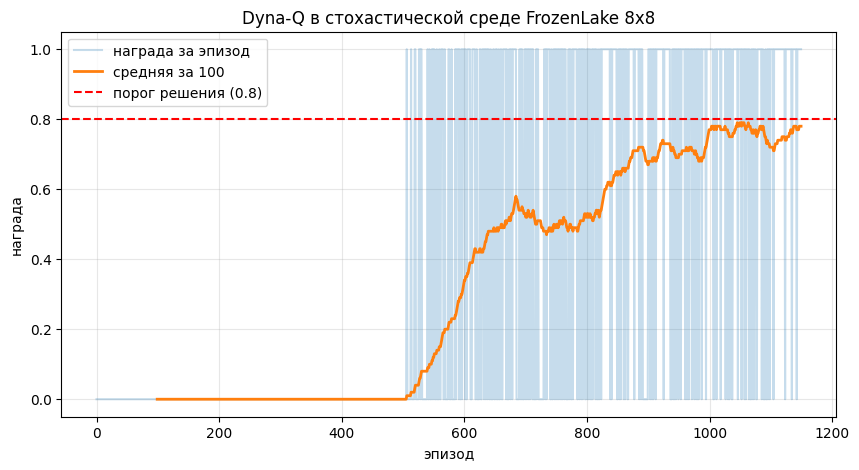

Решено на эпизоде 1160 | Средняя за 100: 0.800


In [19]:
# Пробуем с разным количеством шагов планирования
# 10 шагов планирования
env = StochasticFrozenLake8x8(success_prob=0.8, slip_seed=42)
dyna_agent = DynaQAgent(
    n_states=env.n_states, n_actions=env.n_actions,
    lr=0.1, gamma=0.99, epsilon=1.0, epsilon_min=0.005,
    epsilon_decay=0.9999, planning_steps=10, seed=0,
)
dyna_rewards = train_agent(
    dyna_agent, env, n_episodes=3000,
    log_every=50, plot_every=50, live_plot=True,
    threshold=0.8, title="Dyna-Q в стохастической среде FrozenLake 8x8",
)
env.close()

Эпизод   50 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.839
Эпизод  100 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.710
Эпизод  150 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.597
Эпизод  200 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.505
Эпизод  250 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.425
Эпизод  300 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.367
Эпизод  350 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.307
Эпизод  400 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.264
Эпизод  450 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.222
Эпизод  500 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.186
Эпизод  550 | награда=    1.0 | Средняя(100)=  0.160 | ε=0.167
Эпизод  600 | награда=    0.0 | Средняя(100)=  0.440 | ε=0.147
Эпизод  650 | награда=    0.0 | Средняя(100)=  0.530 | ε=0.120
Эпизод  700 | награда=    0.0 | Средняя(100)=  0.560 | ε=0.102
Эпизод  750 | награда=    1.0 | Средняя(100)=  0.570 | ε=0.084
Эпизод  800 | награда=    1.0 | Средняя(100)=  0.580 | 

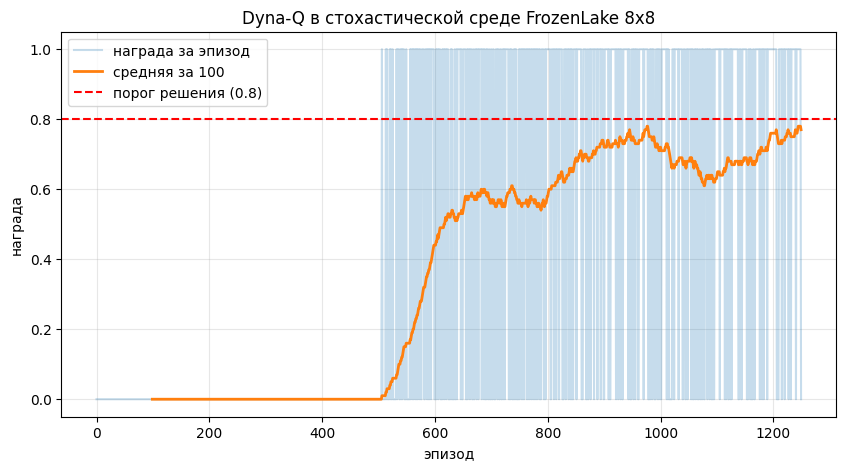

Решено на эпизоде 1262 | Средняя за 100: 0.800


In [20]:
# 20 шагов планирования
env = StochasticFrozenLake8x8(success_prob=0.8, slip_seed=42)
dyna_agent = DynaQAgent(
    n_states=env.n_states, n_actions=env.n_actions,
    lr=0.1, gamma=0.99, epsilon=1.0, epsilon_min=0.005,
    epsilon_decay=0.9999, planning_steps=20, seed=0,
)
dyna_rewards = train_agent(
    dyna_agent, env, n_episodes=3000,
    log_every=50, plot_every=50, live_plot=True,
    threshold=0.8, title="Dyna-Q в стохастической среде FrozenLake 8x8",
)
env.close()

Эпизод   50 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.839
Эпизод  100 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.710
Эпизод  150 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.597
Эпизод  200 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.505
Эпизод  250 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.425
Эпизод  300 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.367
Эпизод  350 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.307
Эпизод  400 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.264
Эпизод  450 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.222
Эпизод  500 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.186
Эпизод  550 | награда=    1.0 | Средняя(100)=  0.180 | ε=0.166
Эпизод  600 | награда=    1.0 | Средняя(100)=  0.390 | ε=0.142
Эпизод  650 | награда=    0.0 | Средняя(100)=  0.460 | ε=0.118
Эпизод  700 | награда=    1.0 | Средняя(100)=  0.530 | ε=0.100
Эпизод  750 | награда=    1.0 | Средняя(100)=  0.570 | ε=0.082
Эпизод  800 | награда=    1.0 | Средняя(100)=  0.610 | 

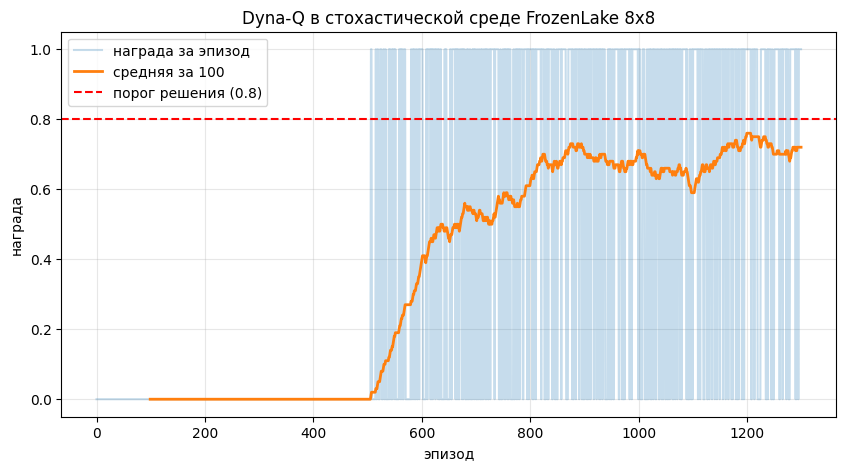

Решено на эпизоде 1325 | Средняя за 100: 0.800


In [21]:
# 30 шагов планирования
env = StochasticFrozenLake8x8(success_prob=0.8, slip_seed=42)
dyna_agent = DynaQAgent(
    n_states=env.n_states, n_actions=env.n_actions,
    lr=0.1, gamma=0.99, epsilon=1.0, epsilon_min=0.005,
    epsilon_decay=0.9999, planning_steps=30, seed=0,
)
dyna_rewards = train_agent(
    dyna_agent, env, n_episodes=3000,
    log_every=50, plot_every=50, live_plot=True,
    threshold=0.8, title="Dyna-Q в стохастической среде FrozenLake 8x8",
)
env.close()

Видим, что обучение с 10 шагами планирования более оптимально

Эпизод   20 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.937
Эпизод   40 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.863
Эпизод   60 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.811
Эпизод   80 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.755
Эпизод  100 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.712
Эпизод  120 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.661
Эпизод  140 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.616
Эпизод  160 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.578
Эпизод  180 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.550
Эпизод  200 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.512
Эпизод  220 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.483
Эпизод  240 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.458
Эпизод  260 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.418
Эпизод  280 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.393
Эпизод  300 | награда=    0.0 | Средняя(100)=  0.000 | ε=0.367
Эпизод  320 | награда=    0.0 | Средняя(100)=  0.000 | 

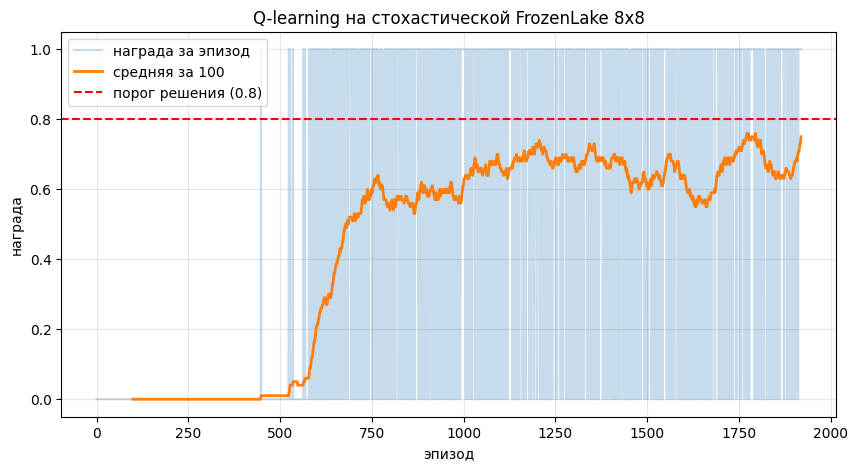

Решено на эпизоде 1930 | Средняя за 100: 0.800


In [ ]:
# обучаем Q-learning агента
env = StochasticFrozenLake8x8(success_prob=0.8, slip_seed=42)
q_agent = QLearningAgent(
    n_states=env.n_states, n_actions=env.n_actions,
    lr=0.1, gamma=0.99, epsilon=1.0, epsilon_min=0.005,
    epsilon_decay=0.9999, seed=0,
)
q_rewards = train_agent(
    q_agent, env, n_episodes=3000,
    log_every=20, plot_every=20, live_plot=True,
    threshold=0.8, title="Q-learning на стохастической FrozenLake 8x8",
)
env.close()

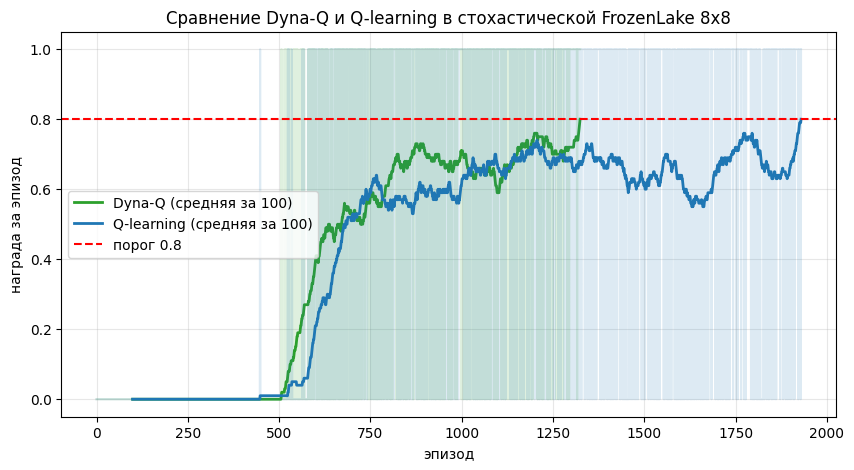

Dyna-Q: средняя за последние 100 = 0.800
Q-learning: средняя за последние 100 = 0.800


In [22]:
fig, ax = plt.subplots(figsize=(10, 5))
for rewards, name, color in [
    (dyna_rewards, "Dyna-Q", "tab:green"),
    (q_rewards, "Q-learning", "tab:blue"),
]:
    ax.plot(rewards, alpha=0.15, color=color)
    avg = moving_average(rewards, 100)
    if len(avg):
        xs = np.arange(99, 99 + len(avg))
        ax.plot(xs, avg, color=color, linewidth=2, label=f"{name} (средняя за 100)")
ax.axhline(0.8, color="red", linestyle="--", label="порог 0.8")
ax.set_xlabel("эпизод"); ax.set_ylabel("награда за эпизод")
ax.set_title("Сравнение Dyna-Q и Q-learning в стохастической FrozenLake 8x8")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

print(f"Dyna-Q: средняя за последние 100 = {np.mean(dyna_rewards[-100:]):.3f}")
print(f"Q-learning: средняя за последние 100 = {np.mean(q_rewards[-100:]):.3f}")

Видим, что оба алгоритма решают задачу, но Dyna-Q за счет планирования обучается за меньшее количество шагов, то есть более эффективно

In [ ]:
import pickle 
pickle.dump(q_agent, open("q_agent.pkl", "wb"))
pickle.dump(dyna_agent, open("dyna_agent.pkl", "wb"))